# ЛР2. Кластеризация методом K-means

Данные: Econom_Cities_data.csv


## 1. EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

DATA_PATH = "Econom_Cities_data.csv"
FEATURES = ["Work", "Price", "Salary"]  # признаки для кластеризации

In [2]:
# разделитель ';', десятичная запятая, пропуски как -9999
df_raw = pd.read_csv(DATA_PATH, sep=";", decimal=",", na_values=[-9999])
df_raw.head()

,City,Work,Price,Salary
0,Amsterdam,1714.0,65.6,49.0
1,Athens,1792.0,53.8,30.4
2,Bogota,2152.0,37.9,11.5
3,Bombay,2052.0,30.3,5.3
4,Brussels,1708.0,73.8,50.5


In [3]:
print(df_raw.isna().sum()) # где пропуски
df_raw[df_raw[FEATURES].isna().any(axis=1)] #какие города

City      0
Work      2
Price     0
Salary    2
dtype: int64


,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


In [4]:
df_raw = df_raw.dropna(subset=FEATURES) # убираем города с пропусками
df_raw = df_raw.reset_index(drop=True).copy()
print("Осталось городов:", len(df_raw))

Осталось городов: 46


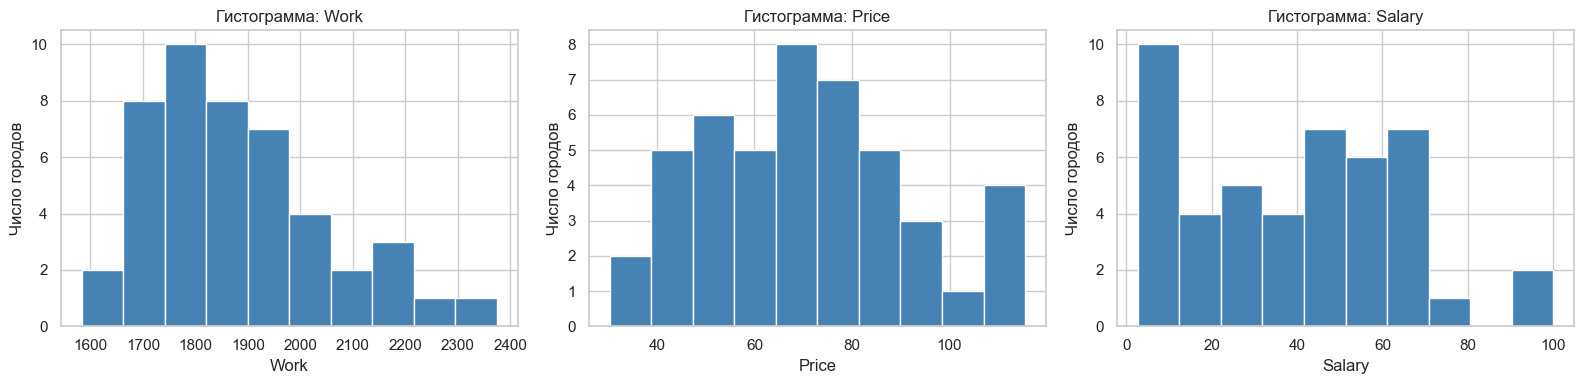

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, FEATURES):
    ax.hist(df_raw[feature], bins=10, color="steelblue", edgecolor="white")
    ax.set_title(f"Гистограмма: {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Число городов")

plt.tight_layout()
plt.show()

После исключения очевидных выбросов распределения выглядят нормально

## 2. Стандартизация

Как и в прошлой работе --- делаем z-стандартизацию.

In [5]:
 df = pd.DataFrame(StandardScaler().fit_transform(df_raw[FEATURES]))

## 3. Кластеризация методом k-means

Расстояние у нас будет евклидово.

Попробуем построить график каменистой осыпи для точного определения числа кластеров:

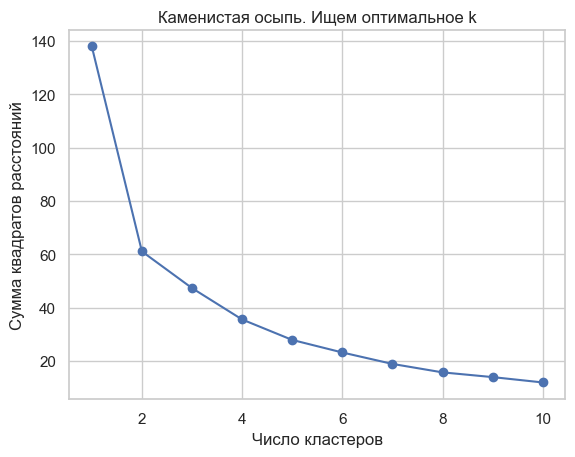

In [6]:
K = range(1, 11)

# Вычисляем значения критерия качества для разного числа кластеров
models = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(df) for k in K]
dist = [model.inertia_ for model in models]

# Строим график каменистой осыпи
plt.plot(K, dist, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()

И заодно посмотрим на средний коэф силуэта

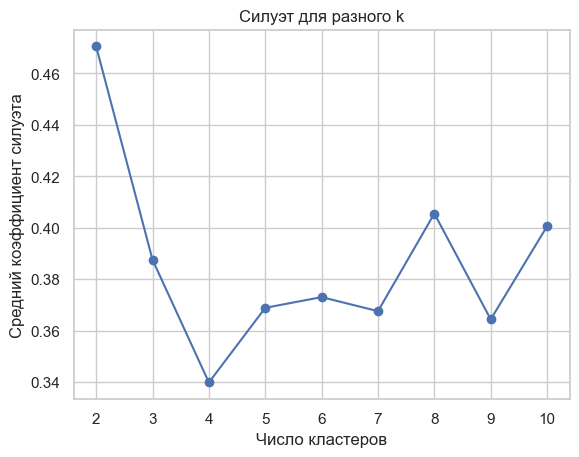

2     0.470
3     0.388
4     0.340
5     0.369
6     0.373
7     0.368
8     0.406
9     0.364
10    0.401
Name: silhouette, dtype: float64

In [28]:
from sklearn.metrics import silhouette_score

X = df.iloc[:, :3]

sil_k = list(range(2, 11))
sil_scores = [silhouette_score(X, models[k - 1].labels_) for k in sil_k]

plt.plot(sil_k, sil_scores, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Средний коэффициент силуэта')
plt.title('Силуэт для разного k')
plt.xticks(sil_k)
plt.show()

pd.Series(sil_scores, index=sil_k, name='silhouette').round(3)

На каменистой осыпи видно выраженный излом при k=2 и менее заметный при k=4 (в прошлой ЛР использовали k=4).

Самый высокий силуэт при k=2, при k=4 наоборот самый низкий.

Рассмотрим оба случая, но сначала введем общие функции.

### 3.0,5. Общие функции

In [7]:
# Провести кластеризацию методом k-средних
def make_k_means(df, k, max_iter=10):
    '''
    k --- кол-во кластеров
    max_iter --- max число итераций
    '''
    X = df.iloc[:, :3]   # только три признака, без столбцов с метками (иначе ломается по типам/колонкам при повторном исп-и)
    model = KMeans(n_clusters=k, random_state=42, max_iter=max_iter, n_init=10, verbose=0, tol=0.0001)
    model.fit(X)
    
    if model.n_iter_ == max_iter:
        print("Не сошлось за ", model.n_iter_ , " итераций") 
    else:
        print("Сошлось за ", model.n_iter_ , " итераций") 

    return model

In [8]:
# Вывести кластеры и города в них
def print_clusters(df, k, cluster_column):
    '''
    k --- число кластеров
    cluster_column --- название колонки кластера
    '''
    for c in range(k):
      print(f"Кластер {c}")
      print(df[df[cluster_column]==c].City.values)
      print()

In [9]:
# Нарисовать 3d результат кластеризации
def plot_3d(df, model, xlabel='Work', ylabel='Price', zlabel='Salary'):
    X = df.iloc[:, :3].to_numpy()
    centers = model.cluster_centers_

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection='3d')

    sc = ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=model.labels_, cmap='tab10')
    cen = ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2],
                     c='black', marker='X', s=200)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_zlabel(zlabel)

    handles, _ = sc.legend_elements()
    names = [f'Кластер {i}' for i in range(len(handles))]
    ax.legend(handles + [cen], names + ['Центроиды'], loc='upper right')

    ax.set_box_aspect(None, zoom=0.85)
    plt.show()

In [10]:
# Вычисление плотности
def mean_dist(df, model, k):
    X = df.iloc[:, :3].to_numpy()
    labels = model.labels_
    centers = model.cluster_centers_
    dist_col=f"dist_{k}"
    
    # евклидово расстояние от каждой точки до центроида её кластера
    dist = np.linalg.norm(X - centers[labels], axis=1)
    
    df_raw[dist_col] = dist
    
    # среднее расстояние по каждому кластеру
    density = df_raw.groupby(labels)[dist_col].mean().round(3)
    density.index.name = 'Кластер'
    
    return density

### 3.1. k=2

In [11]:
k = 2
cluster_col = f"cluster_{k}"
model2 = make_k_means(df, k)

#  Приписываем для каждого города его кластер
df[cluster_col] = model2.labels_
df_raw[cluster_col] = model2.labels_
df_raw.groupby(cluster_col)[FEATURES].mean().round(1)

Сошлось за  3  итераций


,Work,Price,Salary
cluster_2,,,
0,1987.9,52.4,16.3
1,1789.2,85.0,59.0


Получили: богатые (1) vs бедные (0)

In [12]:
print_clusters(df_raw, k, cluster_col)

Кластер 0
['Athens' 'Bogota' 'Bombay' 'Buenos_Aires' 'Caracas' 'Hong_Kong'
 'Johannesburg' 'Kuala_Lumpur' 'Lagos' 'Lisbon' 'Manila' 'Mexico_City'
 'Nairobi' 'Nicosia' 'Panama' 'Rio_de_Janeiro' 'San_Paulo' 'Seoul'
 'Singpore' 'Taipei' 'Tel_Aviv']

Кластер 1
['Amsterdam' 'Brussels' 'Chicago' 'Copenhagen' 'Dublin' 'Dusseldorf'
 'Frankfurt' 'Geneva' 'Helsinki' 'Houston' 'London' 'Los_Angeles'
 'Luxembourg' 'Madrid' 'Milan' 'Montreal' 'New_York' 'Oslo' 'Paris'
 'Stockholm' 'Sydney' 'Tokyo' 'Toronto' 'Vienna' 'Zurich']



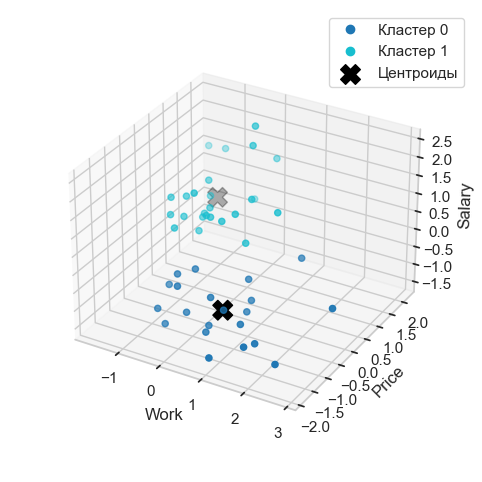

In [13]:
plot_3d(df, model2)

In [14]:
# Считаем среднее расстояние от точки до центроида для каждого кластера
density2 = mean_dist(df, model2, k)
density2

Кластер
0    1.070
1    1.026
Name: dist_2, dtype: float64

Нельзя назвать кластеры очень компактными, средние расстояния большие = плотность недостаточно высокая.

### 3.2. k=4

In [15]:
k = 4
cluster_col = f"cluster_{k}"
model4 = make_k_means(df, k)

#  Приписываем для каждого города его кластер
df[cluster_col] = model4.labels_
df_raw[cluster_col] = model4.labels_
df_raw.groupby(cluster_col)[FEATURES].mean().round(1)

Сошлось за  6  итераций


,Work,Price,Salary
cluster_4,,,
0,1801.2,75.8,55.0
1,2133.5,54.2,16.1
2,1763.8,104.6,67.6
3,1855.5,50.8,16.6


Получили:

0 --- развитые города

1 --- бедные с длинным рабочим годом

2 --- богатые

3 --- бедные 

In [16]:
print_clusters(df_raw, k, cluster_col)

Кластер 0
['Amsterdam' 'Brussels' 'Chicago' 'Dublin' 'Dusseldorf' 'Frankfurt'
 'Houston' 'London' 'Los_Angeles' 'Luxembourg' 'Milan' 'Montreal'
 'New_York' 'Paris' 'Sydney' 'Toronto' 'Vienna']

Кластер 1
['Bogota' 'Bombay' 'Caracas' 'Hong_Kong' 'Kuala_Lumpur' 'Manila' 'Panama'
 'Singpore' 'Taipei' 'Tel_Aviv']

Кластер 2
['Copenhagen' 'Geneva' 'Helsinki' 'Madrid' 'Oslo' 'Stockholm' 'Tokyo'
 'Zurich']

Кластер 3
['Athens' 'Buenos_Aires' 'Johannesburg' 'Lagos' 'Lisbon' 'Mexico_City'
 'Nairobi' 'Nicosia' 'Rio_de_Janeiro' 'San_Paulo' 'Seoul']



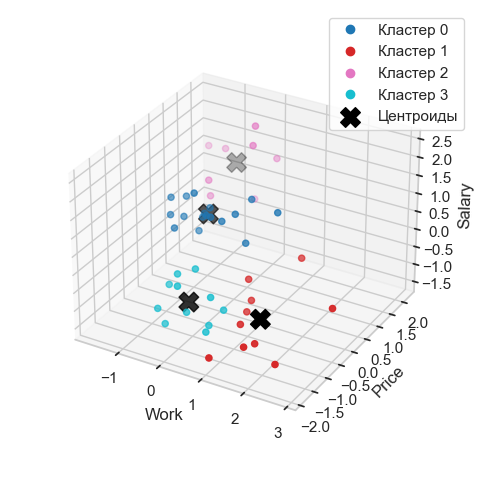

In [17]:
plot_3d(df, model4)

In [18]:
# Считаем среднее расстояние от точки до центроида для каждого кластера
density4 = mean_dist(df, model4, k)
density4

Кластер
0    0.712
1    0.981
2    1.035
3    0.652
Name: dist_4, dtype: float64

Кластеры 0 и 3 заметно компактнее. В целом такое разбиение выглядит "разумнее" с т.з. плотности.

## 4. Итоги

Рассмотрели 2 способа кластеризации: на 2 и 4 кластера.

k=2: это богатые города vs бедные. Богатые = выше з/п и цены, меньше кол-во рабочих часов в год. Бедные = ниже з/п и цены, больше рабочих часов.

k=4: богатые, развивающиеся, бедные и бедные с самым болшим рабочим годом.

При k=4 кластеры в среднем компактнее, но это ожидаемо: с ростом k плотность закономерно увеличивается. Силуэт же учитывает еще и "разделенность" кластеров и он имеет лучшее значение при k=2. Получается, что при k=4 наши "изначальные" 2 группы ("богатые vs бедные") делятся на 2 близкие подгруппы каждая. 